In [1]:
import sys
sys.path.append("../src")
import numpy as np
import matplotlib.pyplot as plt
from tfdr_sim import time_axis, simulate_received, cross_correlate, estimate_distance, V

t = time_axis()

## 실험 1 (고장 두 개 구분하기) 예상
- 30m + 33m: 봉우리 두 개로 보일 것이다
  - 이유: 지연 시간 차이 = 2 × 3 / (2×10^8) = 30 ns. 압축된 덩어리 폭(약 20 ns)보다 넓어서 겹치지 않는다.
- 30m + 31m: 봉우리 한 개로 뭉쳐 보일 것이다
  - 이유: 지연 시간 차이 = 10 ns. 덩어리 폭보다 좁아서 두 덩어리가 겹친다.
- 31m 경우 뭉친 봉우리는 33m 경우의 봉우리 하나보다 높을 것이다.
    - 이유: 두 반사파 모두 Γ = -0.5로 같은 부호이고, 10 ns 어긋남은 200 MHz 진동(주기 5 ns) 2번 차이라서 위상이 맞아 더해질 것이다.

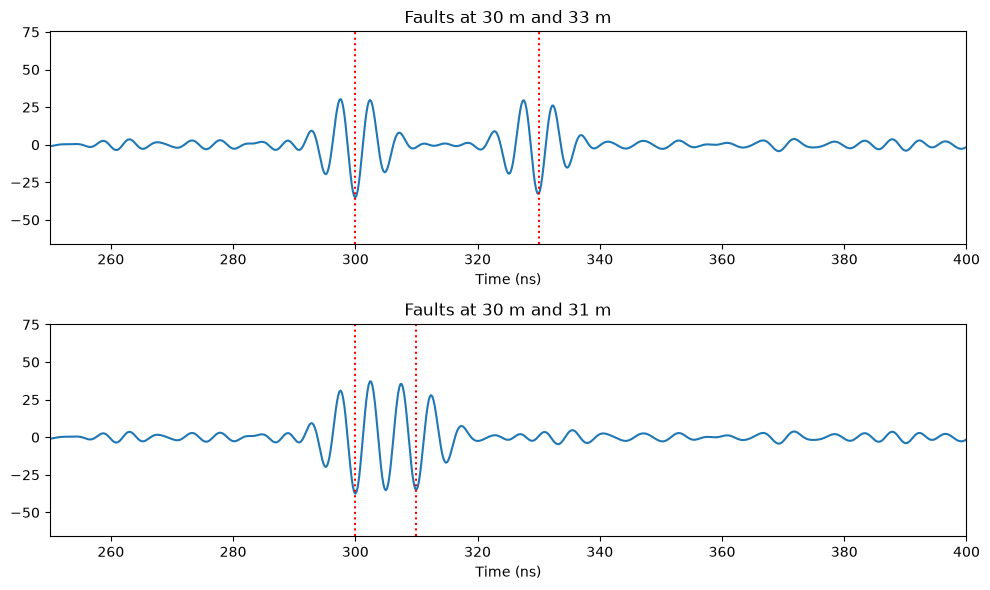

In [2]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))
for a, d2 in zip(ax, [33, 31]):
    ref, rx = simulate_received(t, [(30, -0.5), (d2, -0.5)],
                                rng=np.random.default_rng(0))
    c, lags = cross_correlate(rx, ref)
    a.plot(lags*1e9, c)
    for d in [30, d2]:
        a.axvline(2*d/V*1e9, color="red", linestyle=":")   # 실제 고장 위치
    a.set_xlim(250, 400)
    a.set_title(f"Faults at 30 m and {d2} m")
    a.set_xlabel("Time (ns)")
plt.tight_layout()
plt.show()

## 실험 1 결과 (예상과 비교)
- 30m + 33m: 봉우리 두 개 -> 맞음
    - 300 ns와 330 ns에 따로 떨어진 덩어리 두 개가 생겼고, 둘 다 가장 깊은 곳이 약 -35였다.
- 30m + 31m: 봉우리 한 개로 뭉침 -> 판단 보류
    - 295~315 ns에 걸친 폭이 넓어진 덩어리 하나로 보인다.
    - 다만 300 ns와 310 ns(실제 고장 위치)에 각각 깊은 골이 있어, 두 개로 구분된 것처럼 보이기도 한다.
- 31m 경우 뭉친 봉우리가 더 높을 것이다 -> 거의 틀림
    - 가장 깊은 곳이 약 -37로, 33m 경우의 봉우리(약 -35)와 거의 같았다.

## 실험 1 해석
- 31m 그래프에서 300, 310 ns에 골이 있는 것은 착시일 가능성이 크다.
    - 처프 중심 주파수 200 MHz 때문에 상호사아관은 5 ns만큼 출렁이고, 골도 300, 305, 310 ns처럼 5 ns 간격으로 원래 생긴다.
    - 10 ns 간격이 5 ns의 정확히 2배라서 골이 우연히 실제 고장 위치와 겹쳤을 수 있다.
    - 구분 여부는 출렁임의 골이 아니라 덩어리의 윤곽(포락선)으로 판단해야 한다.
- 뭉친 봉우리가 높아지지 않은 이유:
    - 두 반사파는 같은 부호이고 진동도 2번 차이로 맞아서 더해지긴 한다.
    - 하지만 덩어리 중심이 10 ns 어긋나 있어서, 한쪽이 가장 클 때 다른 쪽은 이미 덩어리 가장자리라 값이 작다.
    - 덩어리 폭이 처음 가정한 약 20 ns보다 좁을 수 있다. 그렇다면 구분 가능한 간격도 2 m보다 작을 수 있다.

## 다음: 포락선으로 다시 확인
- 33m, 31m, 30.5m를 포락선(nb.abs(hilbert(c)))으로 그려서, 혹이 몇 개인지로 구분 가능 여부를 판단한다.

## 실험 1-추가 (포락선으로 구분 여부 확인) 예상
- 33m (간격 30 ns): 혹 2개
- 31m (간격 10 ns): 혹 2개 (이유: 합친 높이가 거의 안 커졌으므로 덩어리 폭이 작을 것이다.)
- 30.5m (간격 5 ns): 혹 1개 (이유: 5 ns는 31m 경우의 절반이라 덩어리가 많이 겹칠 것이다.)
- 따라서 구분 가능한 최소 간격은 약 0.5 ~ 1m 사이일 것이다.

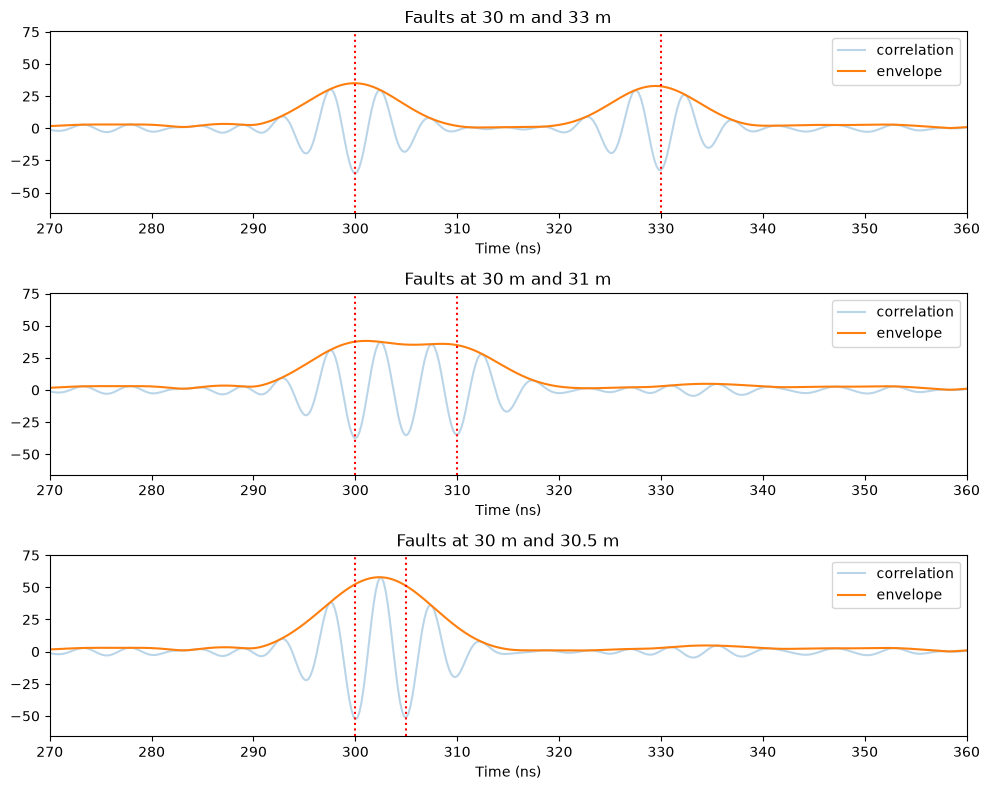

In [3]:
from scipy.signal import hilbert

fig, ax = plt.subplots(3, 1, figsize=(10, 8))
for a, d2 in zip(ax, [33, 31, 30.5]):
    ref, rx = simulate_received(t, [(30, -0.5), (d2, -0.5)],
                                rng=np.random.default_rng(0))
    c, lags = cross_correlate(rx, ref)
    a.plot(lags*1e9, c, alpha=0.3, label="correlation")
    a.plot(lags*1e9, np.abs(hilbert(c)), label="envelope")
    for d in [30, d2]:
        a.axvline(2*d/V*1e9, color="red", linestyle=":")
    a.set_xlim(270, 360)
    a.set_title(f"Faults at 30 m and {d2} m")
    a.legend()
    a.set_xlabel("Time (ns)")
plt.tight_layout()
plt.show()

## 실험 1-추가 (포락선으로 구분 여부 확인) 결과
- 33m (간격 30 ns): 혹 2개 -> 맞음
    - 300 ns와 330 ns에 혹이 하나씩 솟고, 사이가 거의 0까지 내려간다. 확실히 구분된다.
- 31m (간격 10 ns): 혹 2개 예상 -> 반만 맞음
    - 300~310 ns에 걸쳐 윗부분이 평평한 고원 모양이다. 사이가 움푹 꺼지지 않아 엄밀히 구분됐다고 하기 어렵다.
    - 하지만 혹 하나짜리보다 확실히 넓어서 두 개가 겹쳐 있다는 것은 알 수 있다. -> 구분의 한계 지점
- 30.5m (간격 5 ns): 혹 1개 -> 맞음
    - 둥근 혹 하나로 완전히 뭉쳤다. 높이가 약 58로, 혹 하나(약 35)보다 훨씬 높다.

## 실험 1-추가 해석
- 덩어리 폭 다시 재기: 33m 그래프의 혹 하나에서 높이의 절반 (약 17)이 되는 지점이 약 295 ns, 305 ns -> 반높이 폭 약 10 ns
    - 처음 가정한 약 20 ns는 덩어리 밑바닥 전체 폭이었다. 분해능을 정하는 기준은 반높이 폭이다.
      - 실제로 간격이 반높이 폭(10 ns)과 같아지는 31m에서 구분이 될락 말락 했다.
- 거리 분해능 = 신호 속도 * 반높이 폭 / 2 = 2×10^8 × 10 ns / 2 = 1 m
- 30.5m에서 크게 높아진 이유: 5 ns 간격은 거의 완전히 겹치고, 200 MHz 진동 한 번 차이라 위상도 맞아서 두 덩어리가 거의 그대로 더해졌다.
  - 31m(10 ns)에서는 덜 겹쳐서 거의 안 높아졌다. → 더해지는 효과는 "얼마나 겹치는가"에 크게 좌우된다.

## 실험 1 결론
- 이 설정(bandwidth 200 MHz)에서 거리 분해능은 약 1 m
  - 3 m 간격: 확실히 구분 / 1 m 간격: 한계 / 0.5 m 간격: 구분 불가

## 실험 1-추가 2 (대역폭과 분해능) 예상
- 대역폭 200 MHz -> 400 MHz로 2배 키우면, 고장 하나일 때 반높이 폭은 약 10 ns가 될 것이다 (이유: 대역폭을 늘려도, 반높이 폭은 변하지 않을 것이다)
- 대역폭 400 MHz에서 30m + 31m는 그대로일 것이다

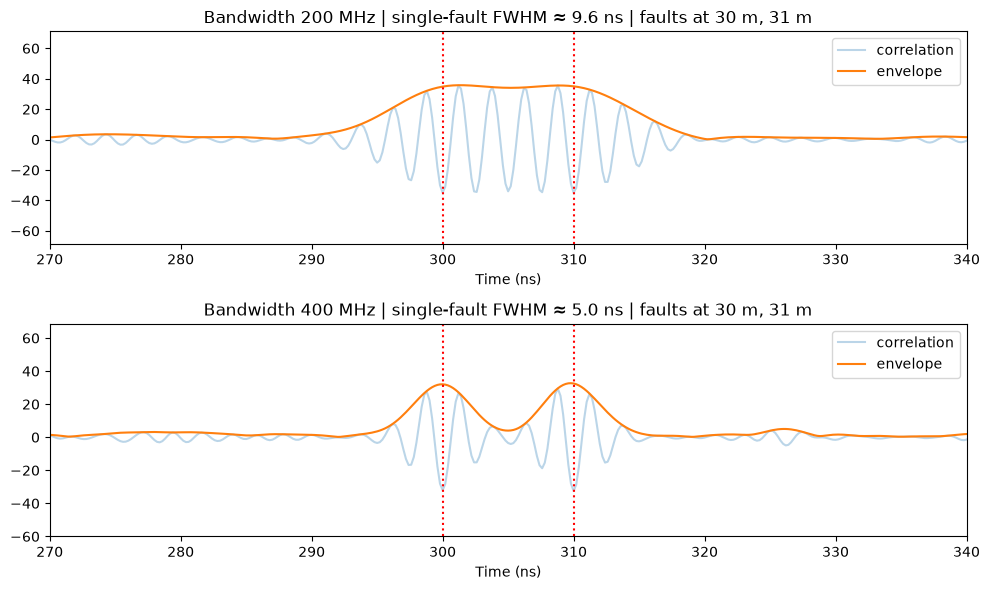

In [4]:
import importlib
import tfdr_sim
importlib.reload(tfdr_sim)                       # 고친 파일을 다시 불러오기
from tfdr_sim import simulate_received, cross_correlate
from scipy.signal import hilbert

def fwhm_ns(env, lags):
    """포락선의 반높이 폭(ns)"""
    above = lags[env >= env.max() / 2]
    return (above.max() - above.min()) * 1e9

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
for a, B in zip(ax, [200e6, 400e6]):
    # ① 고장 하나로 반높이 폭 재기
    ref, rx = simulate_received(t, [(30, -0.5)], rng=np.random.default_rng(0),
                                fc=400e6, bandwidth=B)
    c, lags = cross_correlate(rx, ref)
    win = (lags > 250e-9) & (lags < 350e-9)
    width = fwhm_ns(np.abs(hilbert(c))[win], lags[win])

    # ② 고장 두 개(30 m, 31 m) 구분 여부
    ref2, rx2 = simulate_received(t, [(30, -0.5), (31, -0.5)], rng=np.random.default_rng(0),
                                  fc=400e6, bandwidth=B)
    c2, lags2 = cross_correlate(rx2, ref2)
    a.plot(lags2*1e9, c2, alpha=0.3, label="correlation")
    a.plot(lags2*1e9, np.abs(hilbert(c2)), label="envelope")
    for d in [30, 31]:
        a.axvline(2*d/V*1e9, color="red", linestyle=":")
    a.set_xlim(270, 340)
    a.set_title(f"Bandwidth {B/1e6:.0f} MHz | single-fault FWHM ≈ {width:.1f} ns | faults at 30 m, 31 m")
    a.legend()
    a.set_xlabel("Time (ns)")
plt.tight_layout()
plt.show()

## 실험 1-추가 2 (대역폭과 분해능) 결과
- 대역폭 200 MHz: 반높이 폭 9.6 ns (중심 주파수 200→400 MHz로 바꿔도 앞 실험의 약 10 ns와 같음 -> 변인 통제 확인)
  - 30m + 31m: 평평한 고원 (구분 한계)
- 대역폭 400 MHz: 반높이 폭 5.0 ns -> 정확히 절반
  - 30m + 31m: 혹 두 개로 확실히 갈라지고, 사이가 거의 0까지 꺼짐
- 예상 1 (반높이 폭 그대로 약 10 ns) -> 틀림
- 예상 2 (30m + 31m 그대로 고원) -> 틀림

## 실험 1-추가 2 해석
- 압축된 봉우리 폭은 보낸 처프의 길이(sigma)가 아니라 처프가 훑는 주파수 범위(대역폭)가 정한다.
  - 정합 필터는 처프 속 여러 주파수를 한 시각에 모아 봉우리를 만든다. 모으는 주파수 범위가 넓을수록 더 날카롭게 모인다.
  - 압축된 폭 = 1 / 대역폭 (스펙트로그램의 "주파수 간격 = 1 / 보는 시간"과 시간, 주파수가 뒤집힌 관계)
- 거리 분해능: 200 MHz -> 약 1 m, 400 MHz -> 약 0.5 m

## 실험 1 최종 결론
- 처프의 길이는 에너지(잡음을 이기는 능력)를, 대역폭은 거리 분해능을 정한다. 처프는 이 둘을 분리할 수 있다.
  - 보낸 처프는 수십 ns 길이지만 압축 후 봉우리는 5 ns까지 좁아졌다.

## 실험 2 (잡음과 성공률) 예상
- 계산 근거: 01에서 받은 신호 비율 2.5 → 상호상관 비율 약 10. 상호상관이 비율을 약 4배 키워 줬다.
  - 이 배율이 잡음 크기와 상관없이 같다고 가정한다.
  - 반사파 봉우리가 잡음보다 2~3배는 커야 안정적으로 찾는다고 본다.
- 잡음 0.5일 때
  - 받은 신호: 비율 1. 반사파와 잡음이 같은 크기라 눈으로는 구분하기 어려울 것이다.
  - 상호상관: 비율 약 4. 성공률 약 90% 이상
- 잡음 1.0: 상호상관 비율 약 2 → 성공률 약 50% 근처
- 잡음 2.0 이상: 상호상관 비율 약 1 이하 → 대부분 실패
- 따라서 성공률이 50% 아래로 떨어지는 잡음은 약 1~2 사이일 것이다.

잡음 0.2: 성공률 100/100
잡음 0.5: 성공률 100/100
잡음 1.0: 성공률 85/100
잡음 2.0: 성공률 17/100
잡음 4.0: 성공률 3/100


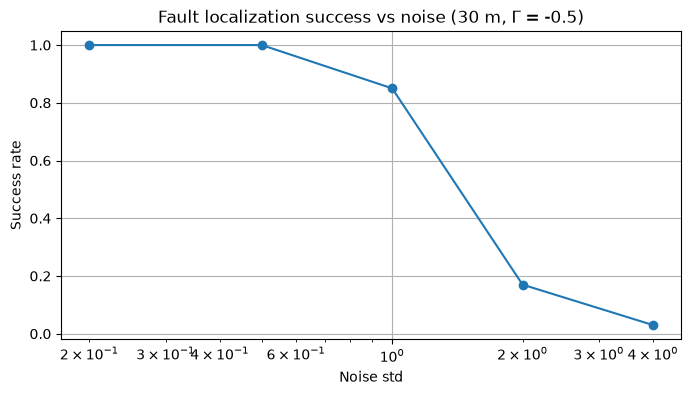

In [5]:
noise_levels = [0.2, 0.5, 1.0, 2.0, 4.0]
n_trials = 100
success_rate = []

for s in noise_levels:
    rng = np.random.default_rng(1)
    hits = 0
    for _ in range(n_trials):
        ref, rx = simulate_received(t, [(30, -0.5)], noise_std=s, rng=rng)
        c, lags = cross_correlate(rx, ref)
        if abs(estimate_distance(c, lags) - 30) < 1:
            hits += 1
    success_rate.append(hits / n_trials)
    print(f"잡음 {s}: 성공률 {hits}/{n_trials}")

plt.figure(figsize=(8, 4))
plt.plot(noise_levels, success_rate, "o-")
plt.xscale("log")
plt.xlabel("Noise std")
plt.ylabel("Success rate")
plt.title("Fault localization success vs noise (30 m, Γ = -0.5)")
plt.grid(True)
plt.show()

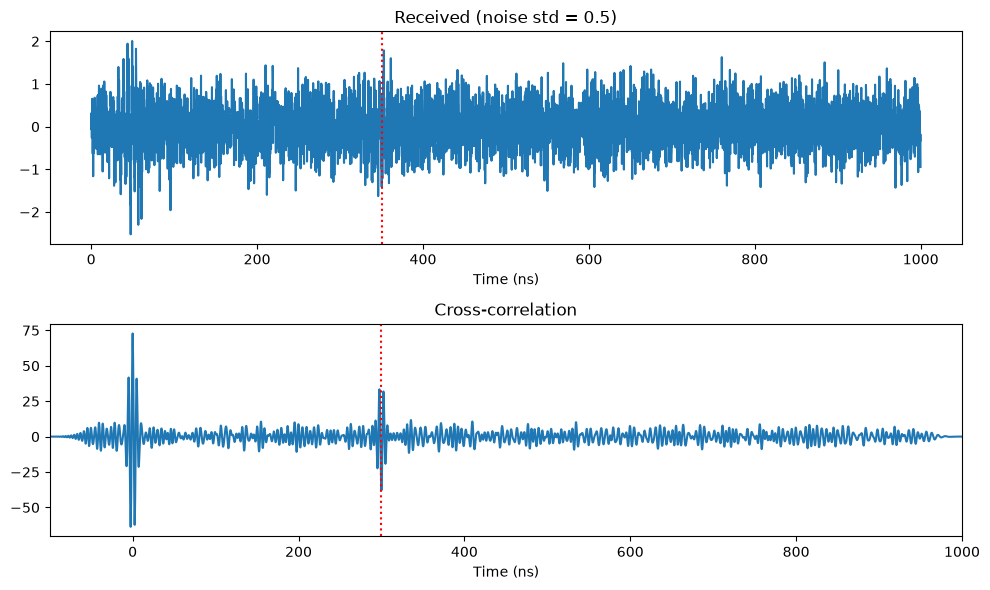

In [7]:
ref, rx = simulate_received(t, [(30, -0.5)], noise_std=0.5,
                            rng=np.random.default_rng(0))
c, lags = cross_correlate(rx, ref)

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(t*1e9, rx)
ax[0].axvline(50 + 300, color="red", linestyle=":")     # 반사파가 와야 할 시각
ax[0].set_title("Received (noise std = 0.5)")
ax[1].plot(lags*1e9, c)
ax[1].axvline(300, color="red", linestyle=":")
ax[1].set_xlim(-100, 1000)
ax[1].set_title("Cross-correlation")
for a in ax:
    a.set_xlabel("Time (ns)")
plt.tight_layout()
plt.savefig("../figures/03_noise_hidden_reflection.png", dpi=150, bbox_inches="tight")
plt.show()

## 실험 2 결과 (예상과 비교)
| 잡음 | 예상 | 실제 | 판정 |
|-----|------|-----|-----|
| 0.2 | ----- |100%| --- |
| 0.5 | 90% 이상 | 100% | 맞음 |
| 1.0 | 약 50% | 85% | 틀림 (실제가 더 좋음) |
| 2.0 | 대부분 실패 | 17% | 맞음 |
| 4.0 | 대부분 실패 | 3% | 맞음 |
- 성공률 50% 경계: 잡음 1~2 사이 → 맞음
- 잡음 0.5 그래프: 받은 신호에서는 반사파 위치(350 ns)에 무엇이 있는지 알아볼 수 없지만, 상호상관에서는 300 ns에 봉우리가 확실히 솟았다.

## 실험 2 해석
- 잡음 1.0에서 예상보다 잘 된 이유: 상호상관의 잡음을 "가장 크게 튄 값(약 ±3)"으로 읽어 배율을 4배로 낮게 잡았다.
  반사파 크기를 받은 신호의 표준편차와 비교했으므로, 상호상관에서도 표준편차와 비교해야 했다. 실제 배율은 4배보다 크다.
- 상호상관이 잡음을 줄이는 원리 (처리 이득):
  - N개 지점을 곱해서 더할 때, 반사파는 같은 부호로 쌓여 N배, 잡음은 제멋대로라 약 √N배만 커진다.
  - 그래서 반사파 ÷ 잡음 비율이 약 √N배 좋아진다.
- 잡음을 0.2 → 0.5로 키우자 상호상관의 잡음 출렁임은 약 ±3 → 약 ±10으로 커졌지만, 반사파 봉우리는 약 35로 그대로였다.
  → 봉우리는 반사파와 기준 처프만으로 정해진다.

## 실험 2-추가 예상
- sigma를 2배로 하면 에너지가 약 2배가 되고, 처리 이득(√N) 때문에 반사파 ÷ 잡음 비율이 약 √2배 좋아질 것이다.
- 그러면 성공률 곡선은 가로축(잡음) 방향으로 √2배만큼 오른쪽으로 옮겨 갈 것이다.
  - 즉 sigma 30 ns의 잡음 X에서의 성공률 ≈ sigma 15 ns의 잡음 X/√2에서의 성공률
- 잡음 2.0에서: sigma 15 ns의 잡음 1.4 성공률과 비슷할 것이다 → 약 50%
- 잡음 2.8에서: sigma 15 ns의 잡음 2.0 성공률(17%)과 비슷할 것이다

sigma 15 ns: [1.0, 0.82, 0.46, 0.16, 0.11, 0.04]
sigma 30 ns: [1.0, 1.0, 0.83, 0.46, 0.18, 0.08]


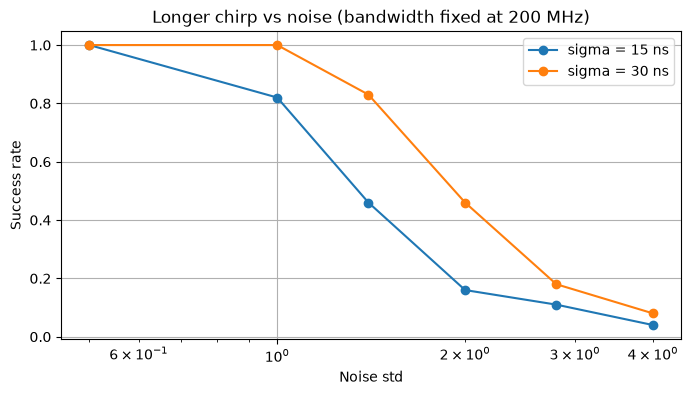

In [7]:
import tfdr_sim
tfdr_sim.T0 = 120e-9   # 처프가 길어지면 0 ns에서 잘리지 않도록 보내는 시각을 늦춤 (두 경우 모두 적용)

noise_levels = [0.5, 1.0, 1.4, 2.0, 2.8, 4.0]
n_trials = 100

plt.figure(figsize=(8, 4))
for sigma in [15e-9, 30e-9]:
    rates = []
    for s in noise_levels:
        rng = np.random.default_rng(1)
        hits = 0
        for _ in range(n_trials):
            ref, rx = simulate_received(t, [(30, -0.5)], noise_std=s, rng=rng, sigma=sigma)
            c, lags = cross_correlate(rx, ref)
            if abs(estimate_distance(c, lags) - 30) < 1:
                hits += 1
        rates.append(hits / n_trials)
    print(f"sigma {sigma*1e9:.0f} ns:", rates)
    plt.plot(noise_levels, rates, "o-", label=f"sigma = {sigma*1e9:.0f} ns")

plt.xscale("log")
plt.xlabel("Noise std")
plt.ylabel("Success rate")
plt.title("Longer chirp vs noise (bandwidth fixed at 200 MHz)")
plt.legend()
plt.grid(True)
plt.show()

## 실험 2-추가 (처프 길이와 잡음) 결과
- 대역폭 200 MHz 고정, sigma만 15 ns → 30 ns (처프 보내는 시각은 두 경우 모두 120 ns)
| sigma 30 ns의 잡음 X | sigma 15 ns의 잡음 X/√2 | 30 ns 성공률 | 15 ns 성공률 |
|---|---|---|---|
| 1.4 | 1.0 | 83% | 82% |
| 2.0 | 1.4 | 46% | 46% |
| 2.8 | 2.0 | 18% | 16% |
- 예상 (곡선이 가로축 방향으로 √2배 오른쪽 이동) → 맞음
- 예상 (sigma 30 ns, 잡음 2.0에서 약 50%) → 실제 46%, 거의 맞음

## 실험 2-추가 해석
- 처프 길이 2배 → 에너지 약 2배 → 처리 이득 √2배 → 같은 성공률을 내는 잡음이 √2배 커도 된다.
- sigma 15 ns 잡음 1.0의 성공률이 지난번 85%에서 82%로 달라진 것은 100회 시행의 통계적 흔들림 범위로 본다.

## 02 노트북 최종 결론
- 처프의 대역폭은 거리 분해능을 정한다: 대역폭 2배 → 반높이 폭 절반 (9.6 → 5.0 ns), 분해능 약 1 m → 0.5 m
- 처프의 길이는 잡음을 견디는 능력을 정한다: 길이 2배 → 견딜 수 있는 잡음 √2배
- 처프는 이 둘을 따로 조절할 수 있다. 이것이 짧은 펄스 대신 처프를 쓰는 이유다.